# <span style="color:magenta">1. Import libraries and config</span>

In [11]:
#for reload and path
import torch
import importlib
from pathlib import Path 
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
import src.pyTorch as py

**Color Configration**

In [1]:
# Define color codes
GREEN = '\033[92m'
BLUE = '\033[94m'
CYAN = '\033[96m'
BOLD = '\033[1m'
RED = '\033[31m'
END = '\033[0m' # Always use this to reset color

**Device configration**  
- Befor doing any other work i have to check the deivice(weather GPU if avialiable or CPU defualt) for my eniter projcet. This helps a lot by reducing prone of error due to device mismatch.
- during preprocessing, training or any other activites the the data and the model must be on the same device otherwise the error encounter it is a common error, if the data on CPU the model should be also on CPU and if the data are on GPU the model also on GPU and vice versal.

In [12]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"{GREEN}Using device: {END}{BOLD}{device}{END}")

Using device: cpu


# <span style="color:magenta">2. Load data</span>
Loading a bunch of image dataset from pyTorch library <u><span style="color:red">FashinMNIST</span></u> dataset.
1. *train_image* have features and also label/targets
2. *test_image* also have in similar manner.

In [ ]:
import torch
from torchvision import transforms, datasets

In [6]:
#download the train and test dataset from FashinMNIST
train_image = datasets.FashionMNIST(     #that is full dataset which have features and target part 
    root = "data",
    train = True,
    download = True,
    transform = transforms.ToTensor()
)
test_image = datasets.FashionMNIST(        #this is also similar but differe in size
    root = "data",   
    train = False,
    download = True,
    transform = transforms.ToTensor()
)
class_name = train_image.classes    
image , label = train_image[0]
display(image.shape, label)          #return the shape of the image(in pixle color channel, hight and with) and the output of the prediction

torch.Size([1, 28, 28])

9

Visualize the image

Image size: torch.Size([1, 28, 28])
Image size: torch.Size([1, 28, 28])


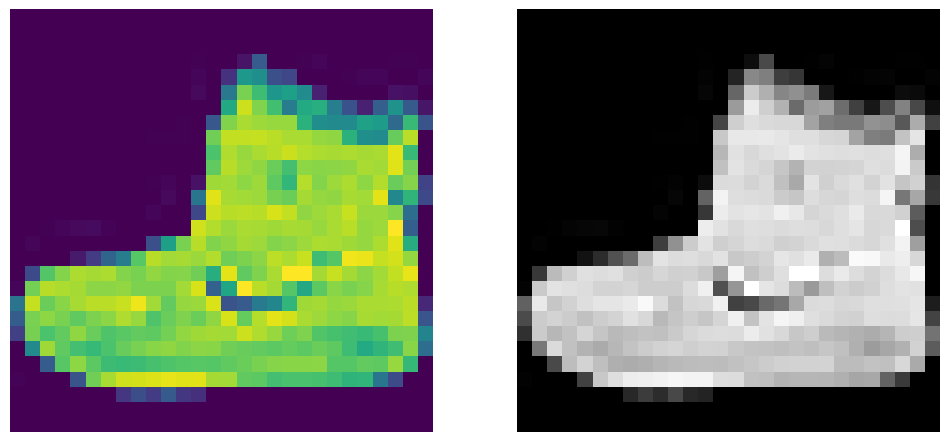

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

In [13]:
#imoprt libraries
import matplotlib.pyplot as plt

def show_image(axis, image, color=None):
    print(f"Image size: {image.shape}")
    plt.figure(figsize=(12, 6))
    if color=="gray":
        axis.imshow(image.squeeze(), cmap="gray")
    else:
        axis.imshow(image.squeeze())
    axis.axis("off")
fig, axis = plt.subplots(1, 2, sharey=True, figsize=(12, 6))   #two spaces
colored, gray = axis

show_image(colored, image=image, color=None)
show_image(gray, image=image, color="gray")
plt.show()

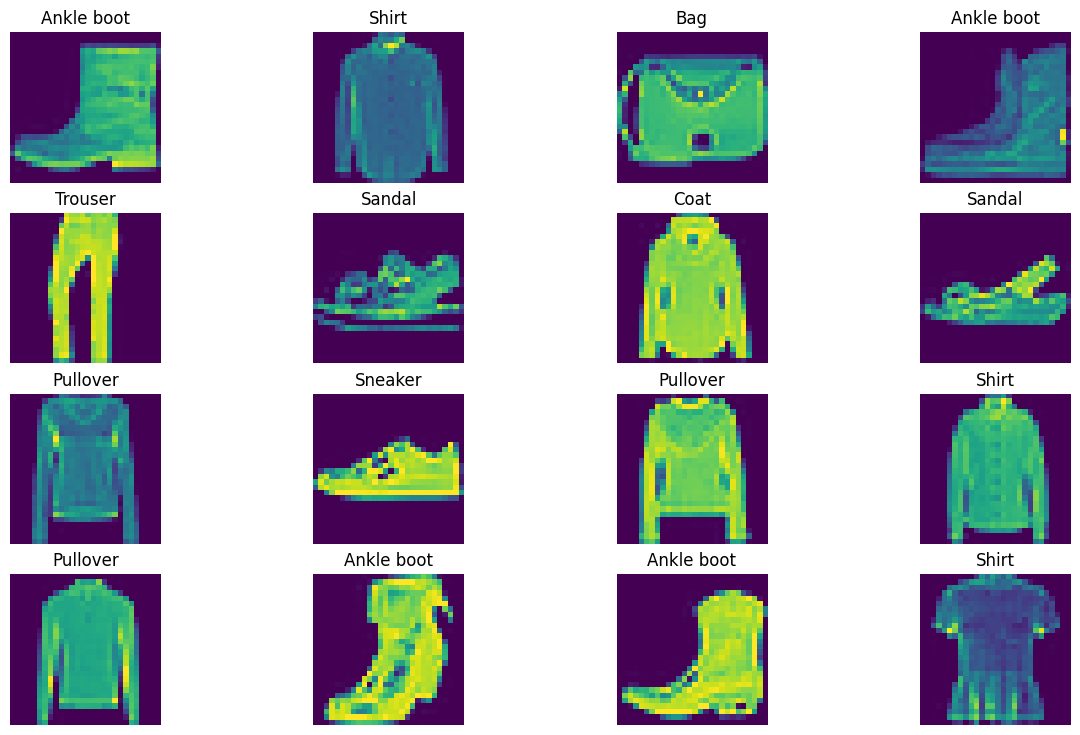

In [14]:
# Plot more images
torch.manual_seed(42)
fig = plt.figure(figsize=(15, 9))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_image), size=[1]).item()
    img, label = train_image[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze())
    plt.title(class_name[label])
    plt.axis(False);

In [15]:
#Import dataloader
from torch.utils.data import DataLoader

BATCH_size = 32
train_dataloader = DataLoader(
    train_image,
    batch_size = BATCH_size,
    shuffle = True        #shuffle for train data is true and for test data is false because we want to keep the order of the test data
)

test_dataloader = DataLoader(
    test_image,
    batch_size = BATCH_size,
    shuffle = False
)

In [56]:
print(f"Train dataloader: {train_dataloader}, \nTest dataloader: {test_dataloader}")
print(len(train_dataloader), len(test_dataloader))   #return the number of batches in the train and test dataloader

Train dataloader: <torch.utils.data.dataloader.DataLoader object at 0x76d499a844d0>, 
Test dataloader: <torch.utils.data.dataloader.DataLoader object at 0x76d4a8b48560>
1875 313


In [17]:
# Check out what's inside the training dataloader
train_features_batch, train_labels_batch = next(iter(train_dataloader))
test_features_batch, test_label_batch = next(iter(test_dataloader))
train_features_batch.shape, train_labels_batch.shape, test_features_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]), torch.Size([32, 1, 28, 28]))

Image size: torch.Size([1, 28, 28])
Label: 6, label size: torch.Size([])


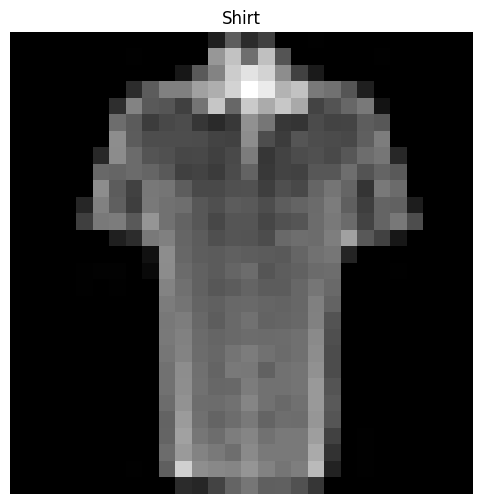

In [58]:
# Show a sample
torch.manual_seed(42)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()
img, label = train_features_batch[random_idx], train_labels_batch[random_idx]
plt.figure(figsize=(15, 6))
plt.imshow(img.squeeze(), cmap="gray")
plt.title(class_name[label])
plt.axis("Off");
print(f"Image size: {img.shape}")
print(f"Label: {label}, label size: {label.shape}")

# <span style="color:magenta">3. Build Baseline Model</span>

### 3.1  Model defination and intialization

In [18]:
#import libraries
import torch.nn as nn

flatten_model = nn.Flatten()                      #it flatten the the image of the model
image = train_features_batch[0]
flattened_image = flatten_model(image)

print(f"Original image shape: {image.shape} -> Flattened image shape: {flattened_image.shape}")

Original image shape: torch.Size([1, 28, 28]) -> Flattened image shape: torch.Size([1, 784])


In [11]:
#flatten nn.Flatten() layer are change the image from (channel, height, width) to (channel, height*width) one feature vector.

print(image.shape), print(flattened_image.shape), print(type(flattened_image))

torch.Size([1, 28, 28])
torch.Size([1, 784])
<class 'torch.Tensor'>


(None, None, None)

In [12]:
#now define the model in subclass 
class FashionModel0(nn.Module):
    def __init__(self, input_shape:int, hidden_layre:int, output_shape:int):
        super().__init__()
        self.layer_stack= nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_layre), 
            nn.Linear(in_features=hidden_layre, out_features=output_shape)
        )
    def forward(self, x):
        return self.layer_stack(x)

star_layer = flattened_image.shape[1]
hidden_layer = 10
out_layer = len(class_name)

#initialize the model
model_0 = FashionModel0(input_shape=star_layer,
                        hidden_layre=hidden_layer,
                        output_shape=out_layer)
model_0

FashionModel0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

### 3.2 Loss, Optimizer and Evaluation

In [ ]:
#import libraries
import requests

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

helper_functions.py already exists, skipping download


In [13]:
# Setup loss function and optimizer
loss_fn = nn.CrossEntropyLoss()        # this is also called "criterion"/"cost function" in some places
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

In [19]:
def train_time_calculator(
        start:float, 
        end:float,
        device: torch.device=None):
    """this function is to calculate the total time for training the model on 
    cpu and gpu device and it is help full"""
    total_time = end - start
    print(f"Train time on {device} is: {total_time:.3f} second")
    return total_time
    

### 3.3 Creating Training Loop and train the model
The **workflow** i follow in this module are:
1. loop through epoch
2. loop through training batch, performing training steps, calculate the training loss per patches.
3. loop through testing batches and so on
4. print out what's happning 
5. time it all

In [ ]:
#import timer, tqdm and accuracy function
from timeit import default_timer as Timer
from tqdm import tqdm
from helper_functions import accuracy_fn

torch.manual_seed(42)
train_test_timer_start = Timer()

#Set the number of epoches(it should be small for now)
epoches = 3

for epoch in tqdm(range(epoches)):
    print(f"Epoch: {epoch}\n --------")
    train_loss = 0

    #add loop for training batches
    for batch, (x_train, y_train) in enumerate(train_dataloader):
        model_0.train()

        # 1. forward pass
        y_prediction = model_0(x_train)

        #2. calculate the loss
        loss = loss_fn(y_prediction,  y_train)
        train_loss += loss #comulate the loss for each batches

        #3. Optimizer zero grad
        optimizer.zero_grad()

        #4. loss backward pass
        loss.backward()

        #5. Optimizer steps
        optimizer.step()

        #Then look what is happning on the background
        if batch % 400 == 0:
            print(f"Looked at {batch * len(x_train)}/ {len(train_dataloader.dataset)} sampels")

    train_loss /= len(train_dataloader)  #average loss per batch

    ##for testing loop
    model_0.eval()  #to evaluation mode
    with torch.inference_mode():
        for x, y in test_dataloader:

            #1. forward pass
            test_prediction = model_0(x)

            #2. calculate the loss of test loop
            test_loss = loss_fn(test_prediction, y)

            #3. if there is accuracy calculate the accuracy of the model
            accuray = accuracy_fn(y_true=y, y_pred=test_prediction.argmax(dim=1))

    average_test_loss = test_loss / len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.5f} | Test loss: {test_loss:.5f}, Test accuracy: {accuray:.2f}")

# Calculate training time      
train_time_end_on_cpu = Timer()
total_train_time_model_0 = train_time_calculator(start=train_test_timer_start, 
                                           end=train_time_end_on_cpu,
                                           device=str(next(model_0.parameters()).device))

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
 --------
Looked at 0/ 60000 sampels
Looked at 12800/ 60000 sampels
Looked at 25600/ 60000 sampels
Looked at 38400/ 60000 sampels
Looked at 51200/ 60000 sampels


 33%|███▎      | 1/3 [00:16<00:33, 16.60s/it]


Train loss: 0.59775 | Test loss: 0.29577, Test accuracy: 93.75
Epoch: 1
 --------
Looked at 0/ 60000 sampels
Looked at 12800/ 60000 sampels
Looked at 25600/ 60000 sampels
Looked at 38400/ 60000 sampels
Looked at 51200/ 60000 sampels


 67%|██████▋   | 2/3 [00:32<00:16, 16.15s/it]


Train loss: 0.47858 | Test loss: 0.27284, Test accuracy: 93.75
Epoch: 2
 --------
Looked at 0/ 60000 sampels
Looked at 12800/ 60000 sampels
Looked at 25600/ 60000 sampels
Looked at 38400/ 60000 sampels
Looked at 51200/ 60000 sampels


100%|██████████| 3/3 [00:47<00:00, 15.99s/it]


Train loss: 0.45628 | Test loss: 0.32685, Test accuracy: 93.75
Train time on cpu is: 47.979 second


In [ ]:
#import library
from torchinfo import summary
summary(model_0, input_size=(1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
FashionModel0                            [1, 10]                   --
├─Sequential: 1-1                        [1, 10]                   --
│    └─Flatten: 2-1                      [1, 784]                  --
│    └─Linear: 2-2                       [1, 10]                   7,850
│    └─Linear: 2-3                       [1, 10]                   110
Total params: 7,960
Trainable params: 7,960
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.01
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.03
Estimated Total Size (MB): 0.04

### 3.4 Make Prediction and evaluate the model

Since my pc have not gpu hardware(not suported) the defualt device is CPU.

In [34]:
py = importlib.reload(py)   #reload the module 

#call the model 
model_1_result = py.model_eval(model=model_0, 
                      data_loader = test_dataloader, 
                      loss_fn = loss_fn, 
                      accuracy_fn = accuracy_fn)

model_1_result    #print the values in that model performance

{'model_name': 'FashionModel0',
 'model_loss': 0.4774632155895233,
 'model_acc': 83.56629392971246}

The baseline model performance:
Precision: 0.84 
Recall: 0.84 
F1 Score: 0.83


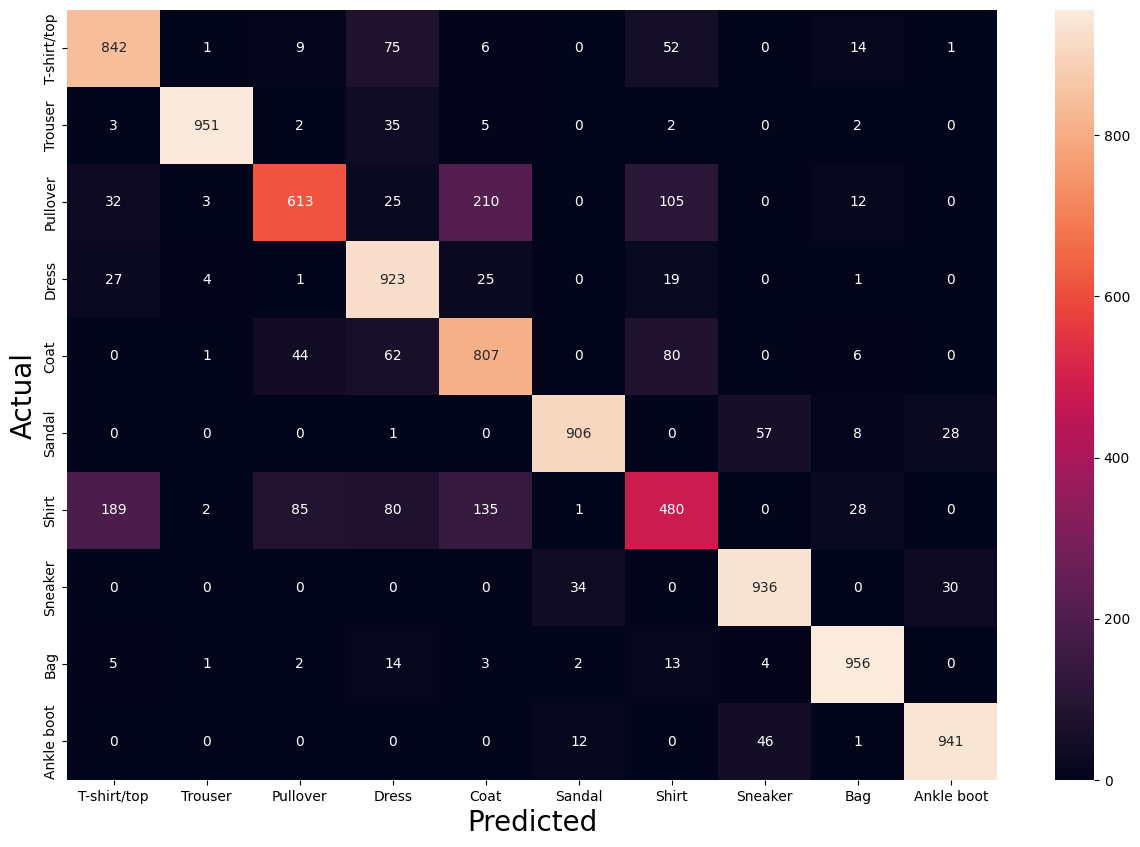

In [18]:
baseline_results = py.evaluate_cnn_metrics(model=model_0,
                                          test_loader=test_dataloader,
                                          device=device)
print(f"{GREEN}{BOLD}The baseline model performance:{END}")
print(f"Precision: {baseline_results['precision']:.2f} \nRecall: {baseline_results['recall']:.2f} \nF1 Score: {baseline_results['f1_score']:.2f}")


#display the confusion matrix using heatmap
py.plot_confusion_matrix(baseline_results["confusion_matrix"], class_names=class_name)

# <span style="color:magenta">4. Non linearity</span>

4.1. Define the Model and assine the model

In [19]:
#create model with non linear function(model definition using non linear function(ReLu))
class noneLinearModel(nn.Module):
    def __init__(self, input:int, hidden:int, output:int):
        super().__init__()
        self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input, out_features=hidden),
        nn.ReLU(),
        nn.Linear(in_features=hidden, out_features=output),
        nn.ReLU())
    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)

In [20]:
#then assign the model and give the parameter
non_linear_model = noneLinearModel(
    input=star_layer,
    hidden=10, 
    output=len(class_name)
)

non_linear_model

noneLinearModel(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
  )
)

4.2 Define loss function and Optimizer

In [21]:
#loss function setup
non_lin_loss_fun = nn.CrossEntropyLoss()

#optimizer
non_lin_optimizer = torch.optim.SGD(params=non_linear_model.parameters(), lr=0.1)

4.3 Training and Testing loop

>I use custom function from other moduls

In [22]:
py = importlib.reload(py)
torch.manual_seed(42)

star_time = Timer()

epoches = 3
for epoch in tqdm(range(epoches)):
    print(f"Epoch: {epoch}\n --------")
    py.train_loop_fnc(non_linear_model, 
                    train_dataloader, 
                    non_lin_loss_fun, 
                    non_lin_optimizer, 
                    accuracy_fn, 
                    device)
    py.test_loop_fnc(non_linear_model,
                    test_dataloader,
                    non_lin_loss_fun,
                    accuracy_fn,
                    device)
end_time = Timer()
total_train_time_non_linear_model = train_time_calculator(
    star_time, 
    end_time,
    device=device
)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
 --------
Train loss: 0.96690 | Train Accuracy: 66.17%



 33%|███▎      | 1/3 [00:16<00:32, 16.47s/it]

Test loss: 0.72918 | Test Accuracy: 72.59%
Epoch: 1
 --------
Train loss: 0.69314 | Train Accuracy: 73.94%



 67%|██████▋   | 2/3 [00:32<00:16, 16.34s/it]

Test loss: 0.72922 | Test Accuracy: 72.39%
Epoch: 2
 --------
Train loss: 0.66002 | Train Accuracy: 74.92%



100%|██████████| 3/3 [00:49<00:00, 16.66s/it]

Test loss: 0.69220 | Test Accuracy: 73.92%
Train time on cpu is: 49.973 second


4.4. Evaluate the model

In [23]:
py = importlib.reload(py)

non_linear_result = py.model_eval(
    non_linear_model,
    test_dataloader,
    non_lin_loss_fun,
    accuracy_fn
)

In [49]:
print(f"{GREEN}{BOLD}The first Model result:{END}")
pprint(model_1_result)
print(f"\n{GREEN}{BOLD}Second Non linear model result:{END}")
pprint(non_linear_result)

The first Model result:
{'model_acc': 83.79592651757189,
 'model_loss': 0.4668132960796356,
 'model_name': 'FashionModel0'}

Second Non linear model result:
{'model_acc': 38.867811501597444,
 'model_loss': 1.5445592403411865,
 'model_name': 'noneLinearModel'}


/home/nigatie/Documents/ML_DL/Deep_Learning/.DL_VE/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nigatie/Documents/ML_DL/Deep_Learning/.DL_VE/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/nigatie/Documents/ML_DL/Deep_Learning/.DL_VE/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

The non linear model performance:
Precision: 0.70 
Recall: 0.74 
F1 Score: 0.71


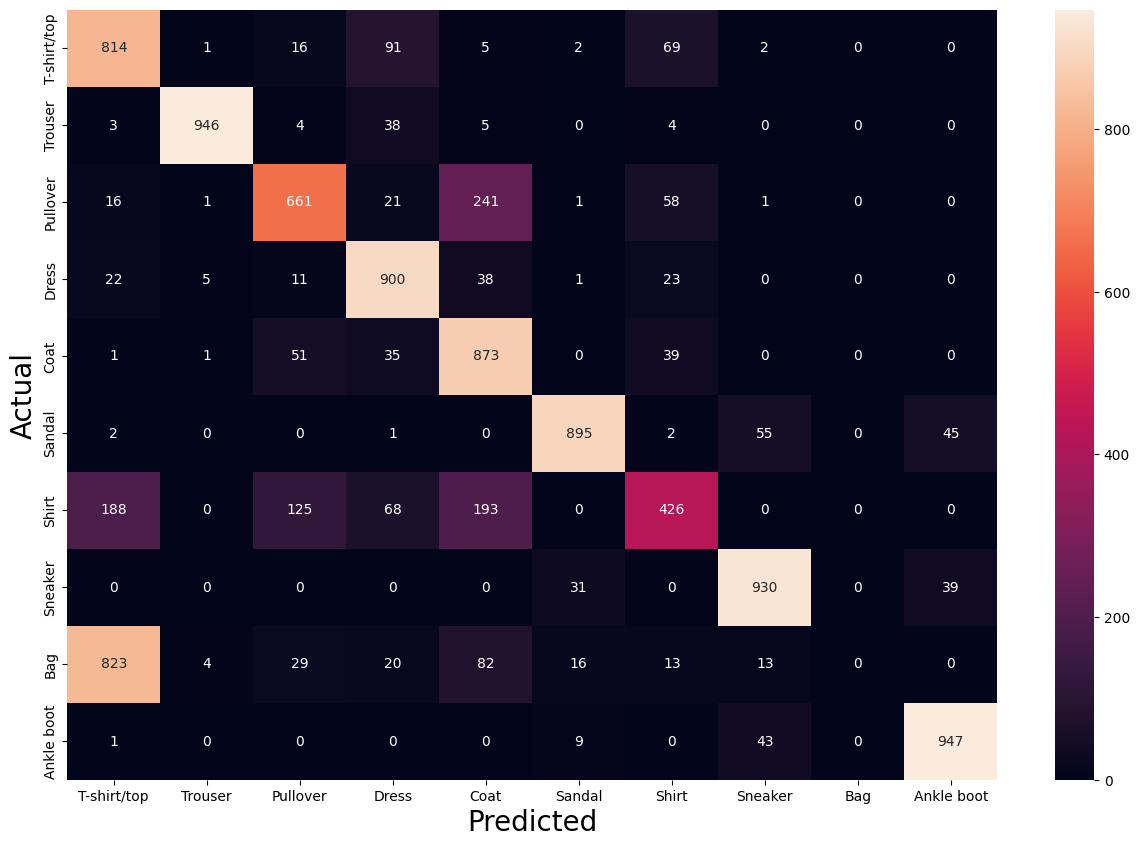

In [24]:
#reload the module agian
py = importlib.reload(py)

non_linear_metrics_result = py.evaluate_cnn_metrics(model=non_linear_model,
                       test_loader=test_dataloader,
                       device=device)
print(f"{GREEN}{BOLD}The non linear model performance:{END}")
print(f"Precision: {non_linear_metrics_result['precision']:.2f} \nRecall: {non_linear_metrics_result['recall']:.2f} \nF1 Score: {non_linear_metrics_result['f1_score']:.2f}")

py.plot_confusion_matrix(non_linear_metrics_result["confusion_matrix"], class_names=class_name)

Overall the model performance is worse than baseline model and it should be improve its performance. especially the precision are low.

# <span style="color:magenta">5. Building CNN</span>

CNN or ConNet is for visual data. i use `TinyVGG` model or CNN model. CNN is best for non structured datas whereas ML models are best for structured data.  

Within the layer there are components
1. Convolutional layer 
2. Pooling layer.  
3. Activation layer


In [25]:
#Define the model in subclass 
class ConvNetModel(nn.Module):
    def __init__(self, input_shape:int, hidden_layer:int, output_shape:int):
        super().__init__()
        self.block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, 
                      out_channels=hidden_layer, 
                      kernel_size=3, 
                      stride=1, 
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_layer, 
                      out_channels=hidden_layer, 
                      kernel_size=3, 
                      stride=1, 
                      padding=1),
                      nn.MaxPool2d(kernel_size=2, 
                                   stride=2))
        self.block_2 = nn.Sequential(
            nn.Conv2d(
                in_channels=hidden_layer,
                out_channels=hidden_layer,
                kernel_size=3,
                padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))
        
        self.Classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_layer*7*7, 
                      out_features=output_shape))
        
    def forward(self, x: torch.Tensor):
        x = self.block_1(x)
        x = self.block_2(x)
        x = self.Classifier(x)
        return x
    
#initalize the model
CNN_model = ConvNetModel(input_shape=1, 
                         hidden_layer=10, 
                         output_shape=len(class_name))
CNN_model

ConvNetModel(
  (block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (Classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

In [26]:
#let's create random data for this case
torch.manual_seed(42)

rand_image = torch.randn(size=(32, 3, 64,64))
"""rand_image is an image generated randomly and it is 32 images which have three color channels and each image have a shape of 64 by 64 pixels(height and width)"""
test_image = rand_image[0]   #i can access the image with indexing and it is the first image of the batch
print(f"Image bach shape: {rand_image.shape} ->[barch size, color, height, width]")
print(f"First image shape: {test_image.shape} -> [color. height, width]")
print(f"Then the first image pexile values are:\n{test_image}")

Image bach shape: torch.Size([32, 3, 64, 64]) ->[barch size, color, height, width]
First image shape: torch.Size([3, 64, 64]) -> [color. height, width]
Then the first image pexile values are:
tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465

In [27]:
convolutional2D = nn.Conv2d(in_channels=3,
                            out_channels=10,
                            kernel_size=(3, 5),
                            padding=0,
                            stride=1)
test_image_conv = convolutional2D(test_image)
"""Our output image size is depend on the convolutional layer and the input image size. in this case my image size have [3, 64,64] ->which is [color channel, height, width] and batch size is 1 since it is single image, the output have 3 dimensions which have similar dimension with the input image but the color channel is changed to 10 because of the out_channel parameter in the convolutional layer and the height and width is changed because of the kernel size and stride and padding. the output image size is [10, 62, 60] -> which is [color channel, height, width]"""
print(f"size of image befor Convolution: {test_image.shape}\nsize of image after Convolution: {test_image_conv.shape}")

size of image befor Convolution: torch.Size([3, 64, 64])
size of image after Convolution: torch.Size([10, 62, 60])


`.state_dict()` - methods returns the learning parameter of the convolutional neural network model, which is also important for saving and reloading the model.  
Those learning parameters are -> weight and biase

In [81]:
convolutional2D.state_dict()

OrderedDict({'weight': tensor([[[[-0.0759, -0.0722, -0.0509,  0.0420,  0.0216],
          [-0.0039, -0.0819,  0.0573,  0.1290, -0.1416],
          [-0.0065,  0.0291, -0.1403, -0.0446, -0.0628]],

         [[-0.0941, -0.0815,  0.0121,  0.0188,  0.1313],
          [ 0.0481, -0.0296, -0.1155, -0.1353,  0.1065],
          [-0.0217, -0.0898, -0.0465, -0.0889,  0.1268]],

         [[-0.1060,  0.0399,  0.0503, -0.0680,  0.1335],
          [ 0.0206,  0.0288, -0.1485,  0.0508, -0.1481],
          [-0.0141,  0.1284,  0.0197,  0.0153,  0.1038]]],


        [[[-0.1196, -0.0698, -0.1063, -0.0619, -0.0350],
          [ 0.0885,  0.0032,  0.0343, -0.0811, -0.1455],
          [-0.0321, -0.1140,  0.0353,  0.0646,  0.1090]],

         [[-0.0279,  0.0087, -0.0586, -0.0133, -0.0293],
          [ 0.0569,  0.0793,  0.0530, -0.0604,  0.0953],
          [ 0.0453, -0.0991,  0.1023,  0.0719, -0.0549]],

         [[-0.0162,  0.0819, -0.1420,  0.1419,  0.1299],
          [ 0.1372, -0.1310,  0.0090, -0.0218, -0.103

What if nn.maxPool2d() model?

In [28]:
maxPloolLayer = nn.MaxPool2d(
    kernel_size=(2)
)

#we have input image "test_image"
print(f"Original images size: {test_image.shape},\nMax pool convoluted image size: {maxPloolLayer(test_image).shape}")

"""For maximium pool convolutional layer the output is reduced by the ratio of the size of the kernel of the layer. that means the output image of height and width is divided by the size of the kernel of the max pool layer kernel."""

print("***************************************************************\n")
#Example with smale image size 
smale_image = torch.randn(1,1,2,2)
print(f"Size of smale iamge: {smale_image.shape}")
print(f"After pass through Maxpool layer the size is reduce to :{maxPloolLayer(smale_image).shape} <- the last two dimesions(height and width) are reduced by half since the size of the kernel of layer is 2")




Original images size: torch.Size([3, 64, 64]),
Max pool convoluted image size: torch.Size([3, 32, 32])
***************************************************************

Size of smale iamge: torch.Size([1, 1, 2, 2])
After pass through Maxpool layer the size is reduce to :torch.Size([1, 1, 1, 1]) <- the last two dimesions(height and width) are reduced by half since the size of the kernel of layer is 2


### Loss function and optimizer
Now set up the loss function and the optimizer  
Our model is multiclass then the loss function should be `nn.CrossEntropyLoss()` and the optimizer is `torch.optim.SGD()` with learning parameter is 0.1 and model parameters.

In [29]:
#loss function 
cnn_loss_fn = nn.CrossEntropyLoss()

#optimizer
cnn_optimizer = torch.optim.SGD(params=CNN_model.parameters(), lr=0.1)

### Training and Testing

It is the time to train the model and make prediction, i have function created before for training and testing the any model just pass teh parameters to that function.

In [30]:
py = importlib.reload(py)
torch.manual_seed(42)

start_time_cnn = Timer()
epoches = 3
for epoch in tqdm(range(epoches)):
    print(f"Epoch: {epoch}\n --------")
    py.train_loop_fnc(CNN_model, 
                    train_dataloader, 
                    cnn_loss_fn, 
                    cnn_optimizer, 
                    accuracy_fn, 
                    device)
    py.test_loop_fnc(CNN_model,
                    test_dataloader,
                    cnn_loss_fn,
                    accuracy_fn,
                    device)
end_time_cnn = Timer()
total_time_CNN = train_time_calculator(start_time_cnn, 
                      end_time_cnn, 
                      device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0
 --------
Train loss: 0.57163 | Train Accuracy: 79.90%



 33%|███▎      | 1/3 [00:37<01:15, 37.64s/it]

Test loss: 0.41227 | Test Accuracy: 85.69%
Epoch: 1
 --------
Train loss: 0.37370 | Train Accuracy: 86.75%



 67%|██████▋   | 2/3 [01:15<00:38, 38.01s/it]

Test loss: 0.34924 | Test Accuracy: 87.36%
Epoch: 2
 --------
Train loss: 0.33254 | Train Accuracy: 88.20%



100%|██████████| 3/3 [01:53<00:00, 37.68s/it]

Test loss: 0.32934 | Test Accuracy: 88.38%
Train time on cpu is: 113.048 second


### Evaluation of the Model

In [31]:
#Then evaluate the model performance
cnn_result = py.model_eval(
                      model=CNN_model, 
                      data_loader = test_dataloader,
                      loss_fn = cnn_loss_fn,
                      accuracy_fn = accuracy_fn)   
print(f"{GREEN}{BOLD}The CNN model result:{END}")
# pprint(cnn_result) 

The CNN model result:


The CNN model metrics:
precision: 0.88463, 
Recal: 0.88
F1 score: 0.88


array([[883,   0,  11,  25,   5,   3,  63,   0,  10,   0],
       [  3, 967,   0,  23,   3,   0,   2,   0,   2,   0],
       [ 19,   1, 746,  13, 125,   0,  95,   0,   1,   0],
       [ 33,   3,   8, 892,  30,   0,  34,   0,   0,   0],
       [  0,   1,  37,  37, 832,   1,  89,   0,   3,   0],
       [  0,   0,   0,   0,   0, 983,   0,  13,   1,   3],
       [180,   1,  49,  30,  76,   0, 650,   0,  14,   0],
       [  0,   0,   0,   0,   0,  25,   0, 960,   0,  15],
       [  1,   1,   2,   3,   3,   2,   7,   5, 976,   0],
       [  0,   0,   0,   0,   0,  11,   0,  40,   1, 948]])

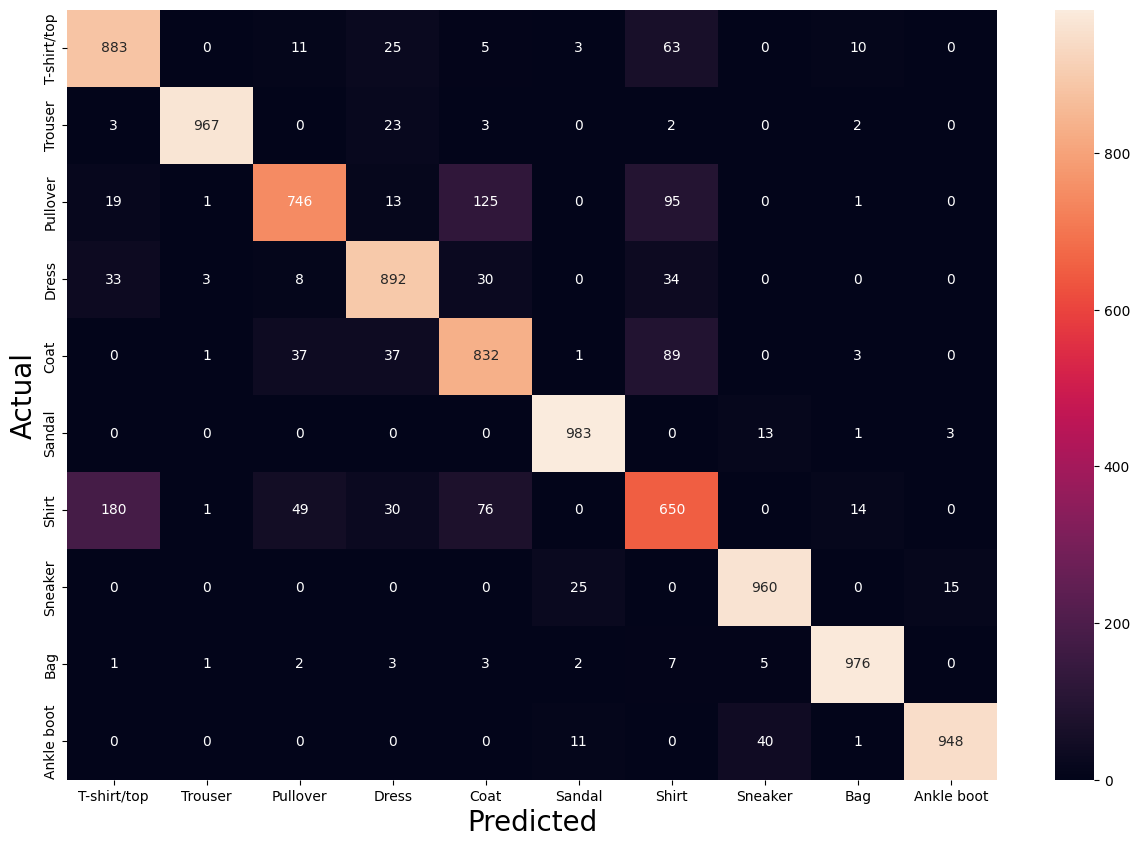

In [32]:
py = importlib.reload(py)

cnn_metrics = py.evaluate_cnn_metrics(CNN_model, test_dataloader, device)
print(f"{GREEN}{BOLD}The CNN model metrics:{END}")
print(f"precision: {cnn_metrics['precision']:.5f}, \nRecal: {cnn_metrics['recall']:.2f}\nF1 score: {cnn_metrics['f1_score']:.2f}")
display(cnn_metrics["confusion_matrix"])


#draw using confusion matrix
py.plot_confusion_matrix(cnn_metrics["confusion_matrix"], class_names=class_name)

From the evaluation of the model it performs well -> which is its accuracy, precision, recal and f1 scare are almost similar(approaching) which is around 88%.  
There need be improvment on some classes like Shirt and T-shirt class <- the model are struggle to identify those classes properly.

In [35]:
comp_models = pd.DataFrame([model_1_result, non_linear_result, cnn_result],
                           index=["Baseline", "Model 1", "CNN model"])
#including the time taken to train the model
comp_models["Time taken(s)"] = [total_train_time_model_0, total_train_time_non_linear_model, total_time_CNN]
comp_models

,model_name,model_loss,model_acc,Time taken(s)
Baseline,FashionModel0,0.477463,83.566294,47.979126
Model 1,noneLinearModel,0.692196,73.921725,49.973293
CNN model,ConvNetModel,0.329337,88.378594,113.048223


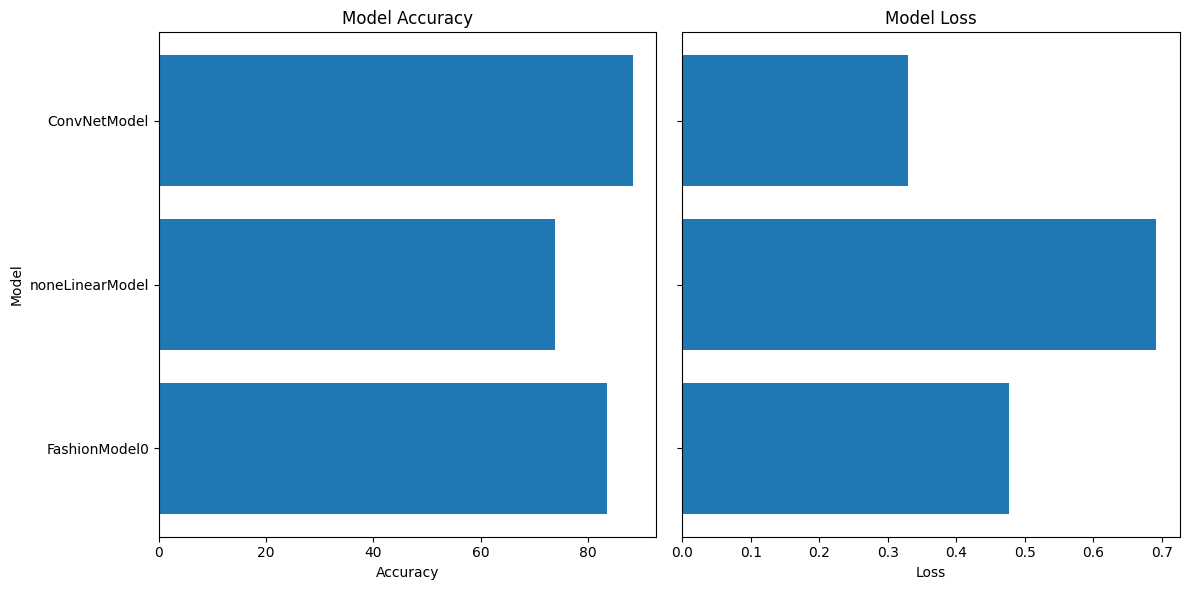

In [36]:
fig, axis = plt.subplots(1, 2, sharey=True, figsize=(12, 6))
first, second = axis

# Accuracy bar plot
first.barh(comp_models["model_name"], comp_models["model_acc"])
first.set_title("Model Accuracy")
first.set_xlabel("Accuracy")
first.set_ylabel("Model")

# Loss bar plot
second.barh(comp_models["model_name"], comp_models["model_loss"])
second.set_title("Model Loss")
second.set_xlabel("Loss")

plt.tight_layout()
plt.show()

From those models CNN model are the winner which have minimium losss error of 0.318 and maximium model  accuracy. model 1 is the worse and perform poorly even worse than the baseline model.   

But the time taken for those three models are also differe, the time taken to train the third model is larger than the first two models which is more than double of each of two models, this shows there should be tradeoff between time and model performance.

In [ ]:
# from torchmetrics import ConfusionMatrix
# from mlxtend.plotting import plot_confusion_matrix

# # 2. Setup confusion matrix instance and compare predictions to targets
# confmat = ConfusionMatrix(num_classes=len(class_name), task='multiclass')
# confmat_tensor = confmat(preds=y_pred_tensor,
#                          target=test_data.targets)

# # 3. Plot the confusion matrix
# fig, ax = plot_confusion_matrix(
#     conf_mat=confmat_tensor.numpy(), # matplotlib likes working with NumPy 
#     class_names=class_name, # turn the row and column labels into class names
#     figsize=(10, 7)
# )

# Save the Model

Save the model which performs well.

In [45]:
#create the directory if there there are not 
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

#then create save path
model_name = "CNN_MODEL.pth"
model_save_path = MODEL_PATH/model_name

#save the model
print(f"saving the model to: {model_save_path}")
torch.save(obj=CNN_model.state_dict(), f=model_save_path)
print(f"The model saved to: {model_save_path}")

saving the model to: models/CNN_MODEL.pth
The model saved to: models/CNN_MODEL.pth
